# Small CNN
Small CNN trained on 128x128 aspect-ratio-preserving padded RGB inputs.
Loads the frozen split from `data/splits/patient_split.csv`

**Note:** `src/preprocessing.py` (Shashank's) is still a stub, so this notebook has a local, temporary
`load_and_pad` placeholder below. Once `src/preprocessing.py` is implemented, delete the placeholder
cell and switch the import back to `from src.preprocessing import load_and_pad`.

In [22]:
import sys
sys.path.append("..")

import kagglehub
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
torch.manual_seed(SEED)

# Prefer a GPU: CUDA on other platforms, MPS (Metal) on Apple Silicon, else fall back to CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Using device:", device)

Using device: mps


## Temporary local preprocessing (remove once `src/preprocessing.py` is implemented)

In [23]:
IMG_SIZE = 128

def load_and_pad(path: str, size: int = IMG_SIZE) -> np.ndarray:
    """TEMPORARY placeholder - mirrors what src/preprocessing.load_and_pad should do.
    Loads an RGB image, preserves aspect ratio, pads to a (size, size) square.
    """
    img = Image.open(path).convert("RGB")
    w, h = img.size
    scale = size / max(w, h)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    img = img.resize((new_w, new_h), Image.BILINEAR)

    canvas = Image.new("RGB", (size, size), (0, 0, 0))
    paste_x = (size - new_w) // 2
    paste_y = (size - new_h) // 2
    canvas.paste(img, (paste_x, paste_y))

    arr = np.asarray(canvas, dtype=np.float32) / 255.0  # scale to [0, 1]
    return arr

## Load the frozen split and build a Dataset/DataLoader
Images are loaded lazily per-batch.

In [24]:
manifest = pd.read_csv("../data/splits/patient_split.csv")
print(manifest["split"].value_counts())

# The manifest only stores filename + category, not an absolute path (those differ per machine).
# The path is rebuild the same way as 00_eda.ipynb (<kagglehub download root>/<category>/<filename>) 
download_path = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))
data_dir = download_path / "cell_images"
if (data_dir / "cell_images").exists():
    data_dir = data_dir / "cell_images"

CLASS_TO_IDX = {"Uninfected": 0, "Parasitized": 1}


class CellDataset(Dataset):
    def __init__(self, df: pd.DataFrame, data_dir: Path):
        self.df = df.reset_index(drop=True)
        self.data_dir = data_dir

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        path = self.data_dir / row["category"] / row["filename"]

        # Load the padded image as a (height, width, channels) array, then rearrange it to
        # (channels, height, width), since PyTorch's conv layers expect the channel dimension first.
        img = load_and_pad(str(path))
        img = torch.from_numpy(img).permute(2, 0, 1)

        label = CLASS_TO_IDX[row["category"]]
        return img, label


train_ds = CellDataset(manifest[manifest["split"] == "train"], data_dir)
val_ds = CellDataset(manifest[manifest["split"] == "val"], data_dir)
test_ds = CellDataset(manifest[manifest["split"] == "test"], data_dir)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

split
train    19124
val       4324
test      4110
Name: count, dtype: int64


## Small CNN

In [29]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes: int = 2):
        super().__init__()
        
        # Conv2d(in_channels, out_channels, kernel_size, padding): in_channels must match the
        # previous layer's out_channels (3 for the RGB input); padding=1 with a 3x3 kernel keeps
        # the spatial size unchanged, so only MaxPool2d(2) halves it (128 -> 64 -> 32 -> 16).
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 128 -> 64
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 64 -> 32
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 32 -> 16
        )

        # Flatten turns the (64, 16, 16) feature map into one vector of 64*16*16 values, which
        # Linear(in_features, out_features) maps down to 128, then to num_classes.
        # Dropout(0.3) randomly zeroes 30% of activations during training to reduce overfitting.
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SmallCNN().to(device)
# Cross Entropy Loss = Binary Cross-Entropy as the classification is binary
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Training loop (validation only - freeze the protocol before touching test_loader)

In [26]:
from sklearn.metrics import f1_score, roc_auc_score, roc_curve, confusion_matrix


def run_epoch(loader, train: bool):
    model.train(mode=train)
    total_loss, correct, n = 0.0, 0, 0
    all_labels, all_preds, all_probs = [], [], []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        n += images.size(0)

        # softmax turns the 2 raw logits (scores from model e.g. (1.2, -0.3)) into class 
        # probabilities that sum to 1; we keep index 1 (probability of "Parasitized") for 
        # ROC-AUC, which needs probabilities rather than hard 0/1 predictions.
        probs = torch.softmax(outputs, dim=1)[:, 1]
        all_labels.extend(labels.cpu().tolist())
        all_preds.extend(preds.cpu().tolist())
        all_probs.extend(probs.detach().cpu().tolist())

    # F1/ROC-AUC/confusion matrix are computed once over the whole epoch's predictions,
    # not averaged per batch - a single batch's TP/FP/FN counts are too small and skewed
    # to give a meaningful score on their own.
    f1 = f1_score(all_labels, all_preds)
    roc_auc = roc_auc_score(all_labels, all_probs)
    cm = confusion_matrix(all_labels, all_preds)
    # fpr/tpr at every threshold - only used for plotting the ROC curve, not training.
    fpr, tpr, _ = roc_curve(all_labels, all_probs)

    return total_loss / n, correct / n, f1, roc_auc, cm, fpr, tpr


NUM_EPOCHS = 5
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_f1": [], "val_f1": [],
    "train_auc": [], "val_auc": [],
}

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_acc, train_f1, train_auc, train_cm, _, _ = run_epoch(train_loader, train=True)
    val_loss, val_acc, val_f1, val_auc, val_cm, val_fpr, val_tpr = run_epoch(val_loader, train=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)
    history["train_auc"].append(train_auc)
    history["val_auc"].append(val_auc)

    print(f"Epoch {epoch}: train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
          f"train_f1={train_f1:.4f} train_auc={train_auc:.4f} "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} "
          f"val_f1={val_f1:.4f} val_auc={val_auc:.4f}")
    print("val confusion matrix:\n", val_cm)

# Keep the final epoch's val ROC points/AUC around for the ROC plot below.
final_val_fpr, final_val_tpr, final_val_auc = val_fpr, val_tpr, val_auc

Epoch 1: train_loss=0.4095 train_acc=0.8106 train_f1=0.8083 train_auc=0.8986 val_loss=0.2584 val_acc=0.8883 val_f1=0.8974 val_auc=0.9669
val confusion matrix:
 [[1728  332]
 [ 151 2113]]
Epoch 2: train_loss=0.1805 train_acc=0.9400 train_f1=0.9399 train_auc=0.9754 val_loss=0.1788 val_acc=0.9477 val_f1=0.9495 val_auc=0.9802
val confusion matrix:
 [[1972   88]
 [ 138 2126]]
Epoch 3: train_loss=0.1449 train_acc=0.9531 train_f1=0.9527 train_auc=0.9838 val_loss=0.1680 val_acc=0.9487 val_f1=0.9507 val_auc=0.9815
val confusion matrix:
 [[1963   97]
 [ 125 2139]]
Epoch 4: train_loss=0.1291 train_acc=0.9571 train_f1=0.9565 train_auc=0.9876 val_loss=0.1539 val_acc=0.9517 val_f1=0.9538 val_auc=0.9847
val confusion matrix:
 [[1959  101]
 [ 108 2156]]
Epoch 5: train_loss=0.1185 train_acc=0.9612 train_f1=0.9607 train_auc=0.9893 val_loss=0.1711 val_acc=0.9454 val_f1=0.9470 val_auc=0.9819
val confusion matrix:
 [[1980   80]
 [ 156 2108]]


## Learning curves
Train vs. validation loss and accuracy across epochs - the proposal's "record learning curves" check.
A widening gap (train still improving, val flat/worsening) signals overfitting.

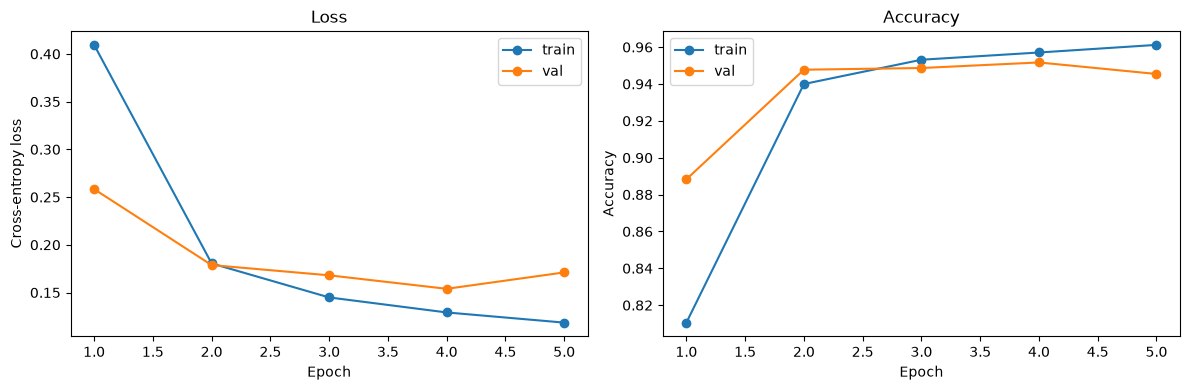

In [27]:
import matplotlib.pyplot as plt

epochs_range = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="train")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="train")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## ROC curve (final epoch, validation set)
The dashed diagonal is the random-guess baseline (AUC = 0.5): a model with no real discriminative
power would produce a ROC curve that tracks this line on average. The further the actual curve
bows toward the top-left corner (high true-positive rate at a low false-positive rate), the better
the model is than chance.

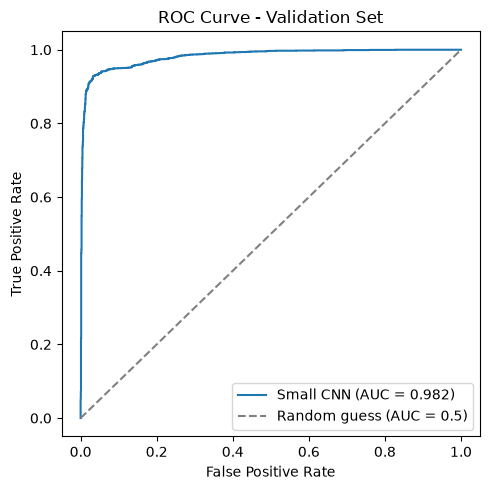

In [28]:
plt.figure(figsize=(5, 5))
plt.plot(final_val_fpr, final_val_tpr, label=f"Small CNN (AUC = {final_val_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend()
plt.tight_layout()
plt.show()